In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Configure plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

X.head()

print('Dataset Shape:', X.shape)
print('\nFirst few rows:')
X.head(10)

Dataset Shape: (150, 4)

First few rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


In [6]:
X.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object

In [7]:
X.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

In [8]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [9]:
X.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


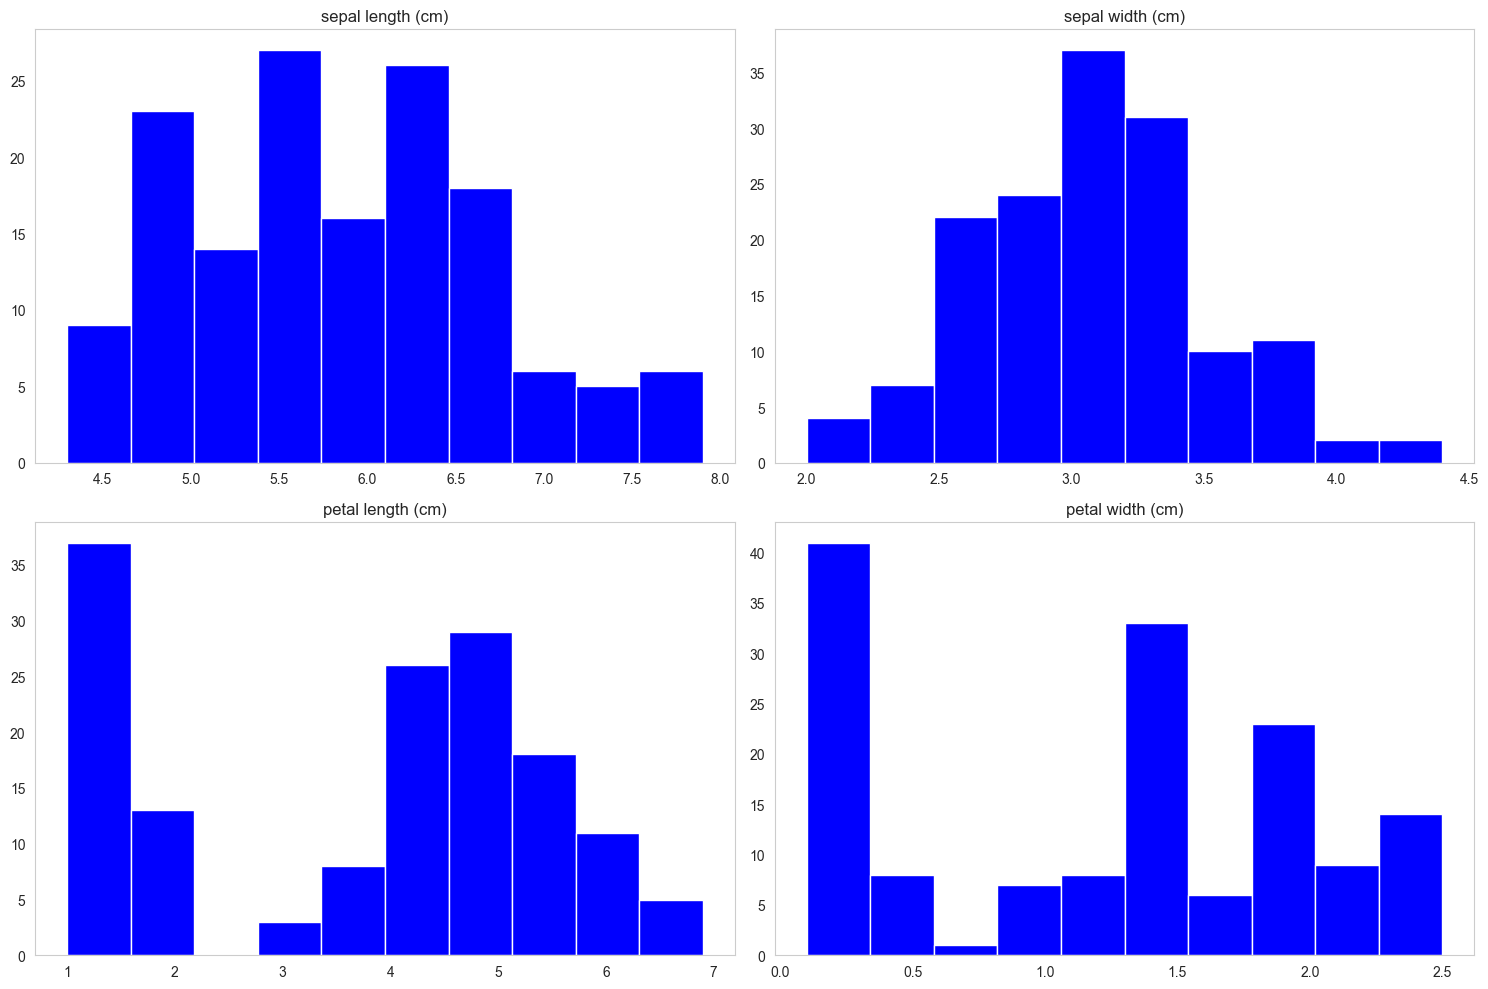

In [10]:
histograms = X.hist(color='blue', grid=False, figsize=(15, 10))
plt.tight_layout()
plt.show()


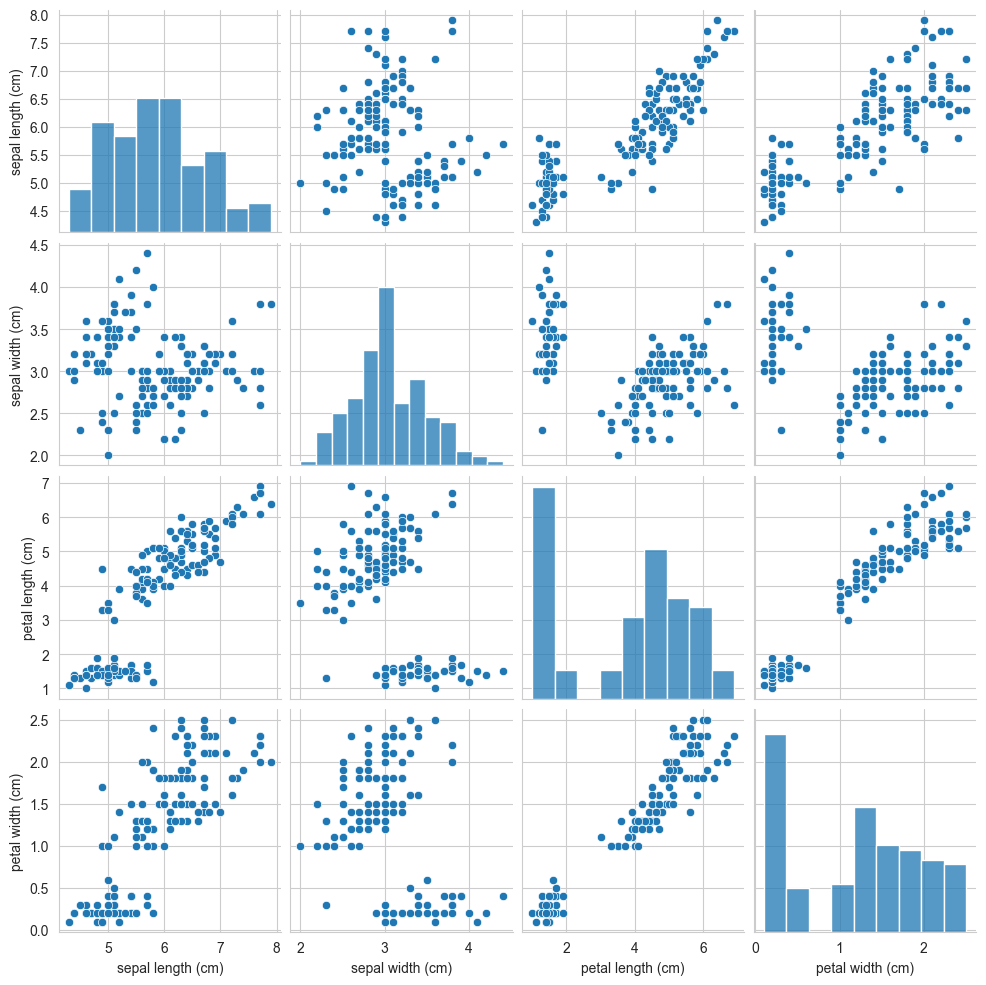

In [11]:
sns.pairplot(X)

<Axes: >

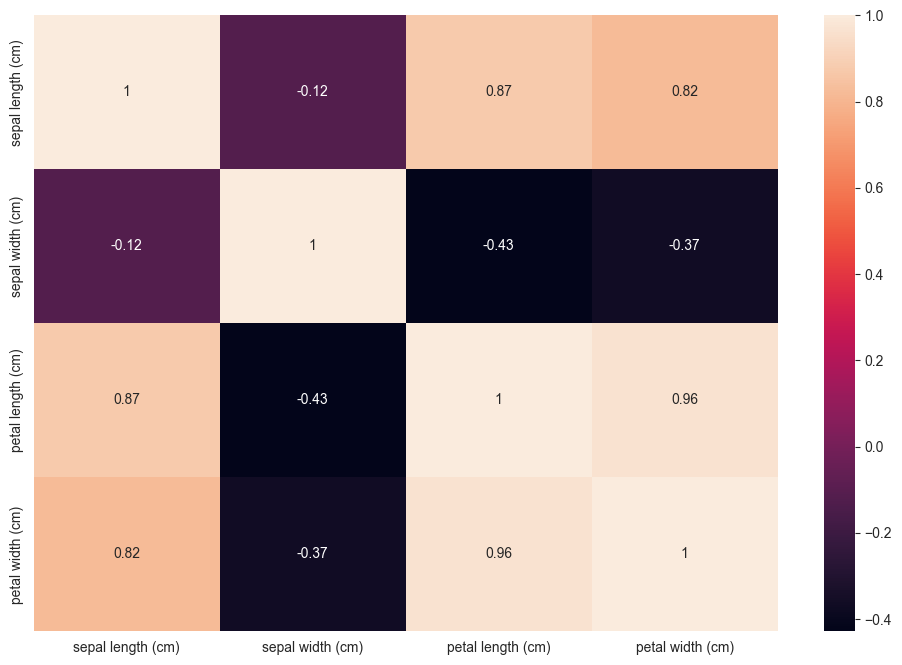

In [12]:
sns.heatmap(X.corr(), annot=True)


Key Observations:
- High positive correlations: Petal Length & Sepal Length, Petal Length and Petal Width
- Sepal Width shows weak or negative correlations with petal width, petal length and sepal length


In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2", "PC3"]
)

pca_df["Species"] = iris.target_names[y]

pca_df.head()

,PC1,PC2,PC3,Species
0,-2.264703,0.480027,0.127706,setosa
1,-2.080961,-0.674134,0.234609,setosa
2,-2.364229,-0.341908,-0.044201,setosa
3,-2.299384,-0.597395,-0.091290,setosa
4,-2.389842,0.646835,-0.015738,setosa


In [15]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

print(
    "Total variance explained:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Explained variance ratio: [0.72962445 0.22850762 0.03668922]
Total variance explained: 99.48%


In [16]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Proportion of variance:", explained_variance)
print("Cumulative variance:", cumulative_variance)

Proportion of variance: [0.72962445 0.22850762 0.03668922]
Cumulative variance: [0.72962445 0.95813207 0.99482129]


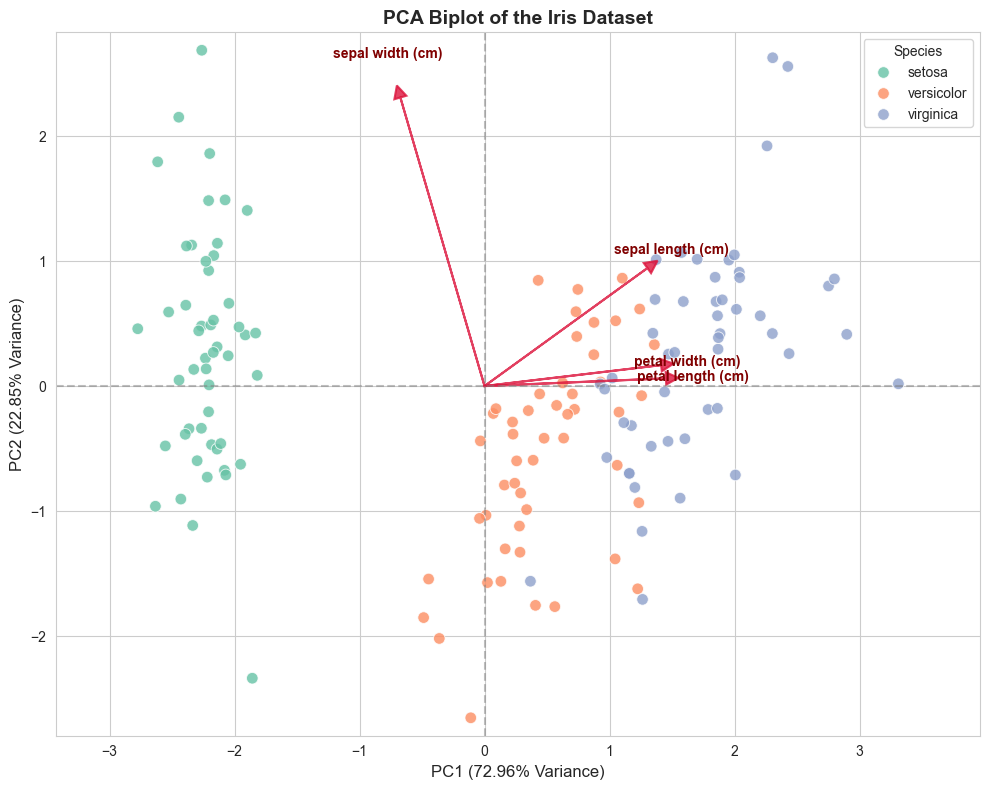

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# 2. Standardize the features (Mean=0, Variance=1)
X_scaled = StandardScaler().fit_transform(X)

# 3. Compute PCA (Top 2 components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_ * 100

# 4. Create a DataFrame for plotting points
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["Species"] = [target_names[i] for i in y]

# 5. Get loading vectors (components)
loadings = pca.components_.T

# 6. Plotting the Biplot
plt.figure(figsize=(10, 8))

# Draw the background grid
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", alpha=0.5)

# Scatter plot of the PCA scores colored by species
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Species",
    palette="Set2",
    alpha=0.8,
    s=70,
)

# Plot the loading arrows (scaled up for visibility on the scatter plot)
scale_factor = 2.5
for i, feature in enumerate(feature_names):
    # Vector coordinates
    x_val = loadings[i, 0] * scale_factor
    y_val = loadings[i, 1] * scale_factor

    # Draw arrow
    plt.arrow(
        0,
        0,
        x_val,
        y_val,
        color="crimson",
        alpha=0.8,
        head_width=0.1,
        head_length=0.1,
        linewidth=1.5,
    )

    # Offset text slightly from arrow tip
    plt.text(
        x_val * 1.15,
        y_val * 1.15,
        feature,
        color="maroon",
        ha="center",
        va="center",
        fontweight="bold",
    )

# Formatting axes labels and title
plt.xlabel(f"PC1 ({var_explained[0]:.2f}% Variance)", fontsize=12)
plt.ylabel(f"PC2 ({var_explained[1]:.2f}% Variance)", fontsize=12)
plt.title("PCA Biplot of the Iris Dataset", fontsize=14, fontweight="bold")
plt.legend(title="Species", loc="best")
plt.axis("equal")
plt.tight_layout()

# Show the plot
plt.show()
